# EV Battery Failure Classification

**Vietnam National University, Ho Chi Minh City - University of Technology**
**Faculty of Computer Science and Engineering**
**Course:** Intelligent Systems
**Instructor:** Assoc. Prof. Quan Thanh Tho

**Group 5**
- Pham Van Thanh - 2570496
- Dong Quang Tri - 2570523

---

## Offline Machine Learning Pipeline (Agent A deliverable)

This notebook implements the Data Scientist's offline workflow described in
section 6 ("Machine Learning Approach") of the project specification: import
and preprocess the EV battery dataset, train and compare three classification
algorithms, select a model based on Failure-class metrics, and export the
trained pipeline for integration into the Streamlit application.

It is a **readable narrative document**: every code cell is preceded by a
markdown cell explaining what it does and why, so the results can be read and
graded on their own without re-running the notebook.

### How to run this notebook

- **Locally (Jupyter / VS Code):** open it from inside the cloned repository
  at `ml_pipeline/notebook/`; the setup cell below finds `ml_pipeline/src/`
  and the dataset CSV automatically via relative paths.
- **Google Colab:** upload or `git clone` the whole repository (the notebook
  needs `ml_pipeline/src/*.py` and the dataset CSV alongside it), open this
  file from `ml_pipeline/notebook/`, then Run All. If the dataset is uploaded
  separately, edit `CSV_PATH` in the setup cell.

Run all cells top to bottom. The final cells write the model bundle to
`ml_pipeline/artifacts/`.

## Setup

Import the shared pipeline code from `ml_pipeline/src/` (the same modules
`train.py` uses, so nothing here is duplicated logic) plus the usual data
science stack. We also fix a consistent color per model configuration so the
same model always has the same color across every chart in this notebook,
and resolve `src/` and the dataset path so the notebook works both locally
and in Colab.

In [1]:
%matplotlib inline
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from sklearn.metrics import precision_recall_curve, ConfusionMatrixDisplay

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)

# --- Resolve ml_pipeline/src so it is importable, both locally and in Colab ---
NOTEBOOK_DIR = Path.cwd()
_candidates = [NOTEBOOK_DIR, NOTEBOOK_DIR.parent, NOTEBOOK_DIR.parent.parent]
ML_PIPELINE_DIR = None
for _c in _candidates:
    if (_c / "src" / "data.py").exists():
        ML_PIPELINE_DIR = _c
        break
if ML_PIPELINE_DIR is None:
    # Colab fallback: adjust this path if you cloned/uploaded the repo elsewhere.
    ML_PIPELINE_DIR = Path("ml_pipeline")
sys.path.insert(0, str(ML_PIPELINE_DIR))

from src import data as data_mod
from src.preprocess import build_preprocessor
from src.models import build_model_configs, SVM_TRAIN_ROW_CAP, RANDOM_STATE
from src.evaluate import compute_metrics, trivial_baseline_metrics, cross_validate_f1_failure
from src.pipeline import split_data, fit_and_evaluate_one, select_best_result, results_as_table, TEST_SIZE
from src.export import (
    build_feature_spec, build_metadata, build_bundle, save_bundle, save_json,
    compute_key_features, key_feature_method_description,
)

# --- Locate the dataset CSV ---
_csv_candidates = [
    ML_PIPELINE_DIR.parent / "ev battery_failure prediction Dataset.csv",
    NOTEBOOK_DIR / "ev battery_failure prediction Dataset.csv",
    Path("ev battery_failure prediction Dataset.csv"),
]
CSV_PATH = next((p for p in _csv_candidates if p.exists()), _csv_candidates[0])
ARTIFACTS_DIR = ML_PIPELINE_DIR / "artifacts"

print("ml_pipeline dir:", ML_PIPELINE_DIR.resolve())
print("dataset csv    :", CSV_PATH.resolve(), "exists:", CSV_PATH.exists())

# --- Chart styling: validated default palette (see ml_pipeline README / dataviz skill) ---
INK_PRIMARY = "#0b0b0b"
INK_SECONDARY = "#52514e"
INK_MUTED = "#898781"
GRID = "#e1e0d9"
SURFACE = "#fcfcfb"

CATEGORICAL_PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
STATUS_CRITICAL = "#d03b3b"
STATUS_GOOD = "#0ca30c"
SEQUENTIAL_BLUE = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]

MODEL_ORDER = [cfg.display_name for cfg in build_model_configs()]
MODEL_COLORS = dict(zip(MODEL_ORDER, CATEGORICAL_PALETTE))

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_PRIMARY,
    "axes.titleweight": "bold",
    "text.color": INK_PRIMARY,
    "xtick.color": INK_SECONDARY,
    "ytick.color": INK_SECONDARY,
    "grid.color": GRID,
    "font.size": 10.5,
    "axes.grid": True,
    "grid.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

ml_pipeline dir: C:\Users\PC\Downloads\HTTM\Assigment\ml_pipeline
dataset csv    : C:\Users\PC\Downloads\HTTM\Assigment\ev battery_failure prediction Dataset.csv exists: True


## 1. Problem Statement and Target Variable

Electric vehicle (EV) batteries degrade and occasionally fail; catching a
failure early supports timely maintenance and avoids safety incidents. This
notebook builds a **binary classifier** for the target column
`battery_failure`:

| Label | Meaning |
|---|---|
| `0` | **No Failure** |
| `1` | **Failure** |

This is deliberately **not** the 3-class state-of-health task explored
elsewhere in this repository's `backend/` directory - that solved a
different problem. Per the project specification (section 6.1), the model
here predicts the binary `battery_failure` column directly, using the
dataset's battery, charging, driving, environmental and maintenance
features. `vehicle_id` and `battery_serial` are record identifiers, not
predictors, and are excluded from the feature matrix.

## 2. Data Loading

Load the CSV with `src.data.load_dataset` (a thin `pandas.read_csv` wrapper)
and inspect its shape and column types before doing anything else.

In [2]:
df = data_mod.load_dataset(str(CSV_PATH))
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

Shape: 20,000 rows x 70 columns


,vehicle_id,vehicle_brand,vehicle_model,vehicle_type,manufacturing_year,battery_manufacturer,battery_chemistry,battery_capacity_kwh,drive_type,odometer_km,vehicle_age_years,fleet_or_private,battery_serial,cycle_count,battery_health_percent,state_of_charge,depth_of_discharge,state_of_health,cell_voltage_avg,cell_voltage_std,pack_voltage,cell_temperature_avg,cell_temperature_max,internal_resistance,charge_efficiency,discharge_efficiency,remaining_capacity,capacity_loss_percent,charging_cycles_last_month,fast_charge_ratio,slow_charge_ratio,average_charge_power_kw,average_charging_time,overnight_charging_ratio,home_charging_ratio,charging_interruptions,overcharge_events,average_speed,average_trip_distance,aggressive_acceleration_score,hard_braking_score,regenerative_braking_usage,highway_driving_ratio,city_driving_ratio,daily_distance,average_ambient_temperature,maximum_temperature,minimum_temperature,humidity,altitude,terrain_type,dust_exposure,last_service_days,cooling_system_health,firmware_updates,previous_faults,maintenance_score,thermal_runaway_risk,voltage_imbalance,temperature_variance,sensor_fault_count,BMS_warning_count,abnormal_voltage_events,battery_stress_index,aging_score,thermal_health_score,charging_quality_score,driving_stress_score,predicted_remaining_life_cycles,battery_failure
0,EV100000,Ford,Mustang Mach-E,Truck,2022.0,Northvolt,NMC,NaN,AWD,290844.3,4.45,Fleet,BAT-10000000,NaN,80.60,65.00,58.74,79.75,3.793,0.0046,383.09,21.75,27.87,0.506,96.50,93.93,31.14,19.40,37.0,0.34,0.63,71.88,47.08,0.16,0.86,2.0,1.0,10.70,128.30,12.02,8.87,48.00,0.55,0.43,205.30,30.22,39.32,15.48,33.54,480.36,Flat,75.07,1316.2,84.84,13.0,2.0,43.16,4.88,13.80,NaN,1.0,NaN,0.0,30.37,73.05,98.14,89.73,47.11,6748.0,0
1,EV100001,Tata,Tiago EV,Truck,2017.0,CATL,NCA,38.71,RWD,182239.5,9.17,Fleet,BAT-10000001,1425.0,61.24,43.32,35.23,60.72,3.744,0.0236,355.68,14.98,27.26,0.861,94.98,92.58,23.71,38.76,7.0,0.25,0.58,74.25,42.20,0.43,0.94,2.0,0.0,117.02,37.13,73.07,77.06,54.11,0.24,0.16,42.27,-23.30,-7.11,NaN,8.66,1185.46,Coastal,41.62,958.1,81.95,19.0,1.0,55.35,11.80,34.30,32.94,0.0,1.0,0.0,67.94,82.50,NaN,NaN,55.38,5211.0,0
2,EV100002,Volkswagen,ID.3,Crossover,2016.0,BYD Battery,LFP,131.29,FWD,249369.3,10.17,Fleet,BAT-10000002,NaN,62.35,68.37,59.60,62.71,3.514,NaN,323.29,33.70,53.79,0.720,93.36,91.92,81.86,37.65,16.0,0.23,0.52,12.24,NaN,0.72,0.55,1.0,1.0,85.66,133.09,87.10,74.57,25.05,0.04,0.57,175.70,-20.21,-4.29,-33.95,42.25,2075.03,Flat,36.20,101.6,81.29,21.0,1.0,93.54,41.69,6.81,32.94,0.0,1.0,0.0,74.84,90.33,60.02,86.84,74.54,4040.0,0
3,EV100003,NaN,Kona Electric,Sedan,2019.0,SK On,NMC,132.35,FWD,134830.2,7.41,Fleet,BAT-10000003,776.0,83.41,63.87,60.77,83.36,3.664,0.0167,267.47,31.28,53.12,0.351,95.60,95.33,110.39,16.59,19.0,0.04,0.92,44.40,225.24,0.85,0.76,3.0,0.0,102.02,90.92,41.91,5.77,86.57,0.89,0.20,137.31,8.25,24.51,-4.09,NaN,2194.54,Desert,39.83,1374.8,94.47,19.0,0.0,45.33,32.16,25.04,32.94,NaN,0.0,0.0,46.94,56.69,66.43,93.93,31.69,NaN,0
4,EV100004,MG,ZS EV,SUV,2017.0,Guoxuan,LTO,25.72,AWD,158026.0,9.56,Private,BAT-10000004,1117.0,78.49,46.59,37.54,76.97,NaN,0.0169,358.30,15.66,31.69,0.425,96.19,93.69,20.19,21.51,18.0,0.25,0.51,44.91,52.72,0.68,0.74,1.0,0.0,102.80,39.01,9.10,34.10,59.24,0.47,0.83,17.85,-14.75,-0.60,-21.71,72.32,1682.91,Desert,32.94,1085.9,90.89,10.0,0.0,52.90,6.01,23.85,32.94,1.0,2.0,3.0,49.07,73.65,95.05,100.00,23.46,7290.0,0


### Column roles

- **Target:** `battery_failure` (1 column).
- **Identifiers (excluded from features):** `vehicle_id`, `battery_serial`.
- **Features:** the remaining 67 columns - 59 numeric, 8 categorical.

In [3]:
numeric_cols = data_mod.get_numeric_columns(df)
categorical_cols = data_mod.get_categorical_columns(df)
feature_cols = data_mod.get_feature_columns(df)

print(f"Feature columns : {len(feature_cols)}")
print(f"  numeric        : {len(numeric_cols)}")
print(f"  categorical    : {len(categorical_cols)} -> {categorical_cols}")
print(f"Identifier columns (excluded): {data_mod.ID_COLS}")
print(f"Target column                : {data_mod.TARGET_COL!r}")

dtype_counts = df[feature_cols].dtypes.astype(str).value_counts()
print("\ndtype counts among feature columns:")
print(dtype_counts.to_string())

Feature columns : 67
  numeric        : 59
  categorical    : 8 -> ['vehicle_brand', 'vehicle_model', 'vehicle_type', 'battery_manufacturer', 'battery_chemistry', 'drive_type', 'fleet_or_private', 'terrain_type']
Identifier columns (excluded): ['vehicle_id', 'battery_serial']
Target column                : 'battery_failure'

dtype counts among feature columns:
float64    59
str         8


### Missing-value profile

Per spec section 6.1, "data preprocessing will include handling missing
values ... required." Almost every column has a small amount of missing
data (roughly 3-5%), so imputation is mandatory, not optional.

In [4]:
missing = data_mod.missing_value_profile(df)
print(f"Columns with at least one missing value: {(missing > 0).sum()} / {len(missing)}")
print(f"Missing-value range among affected columns: {missing[missing > 0].min():.2f}% - {missing[missing > 0].max():.2f}%")
missing.head(15).to_frame("missing_percent")

Columns with at least one missing value: 67 / 70
Missing-value range among affected columns: 3.05% - 4.94%


,missing_percent
fast_charge_ratio,4.94
average_speed,4.92
manufacturing_year,4.91
home_charging_ratio,4.90
sensor_fault_count,4.84
charging_interruptions,4.82
state_of_charge,4.82
capacity_loss_percent,4.78
state_of_health,4.78
slow_charge_ratio,4.74


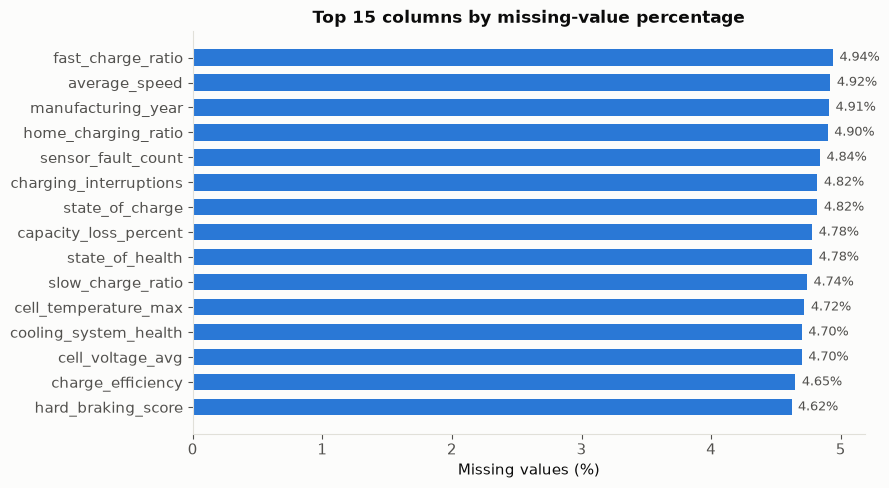

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
top15 = missing.head(15).iloc[::-1]
ax.barh(top15.index, top15.values, color=CATEGORICAL_PALETTE[0], height=0.65)
ax.set_xlabel("Missing values (%)")
ax.set_title("Top 15 columns by missing-value percentage")
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
for y, v in enumerate(top15.values):
    ax.text(v + 0.05, y, f"{v:.2f}%", va="center", fontsize=9, color=INK_SECONDARY)
plt.tight_layout()
plt.show()

## 3. Class Imbalance Analysis - the Accuracy Trap

This is the single most important fact about this dataset: **Failure is
rare (6.92%)**. Any evaluation that reports accuracy alone will be
misleading, because a model that never predicts Failure already looks
excellent by that measure. We demonstrate this concretely before training
anything, since it motivates every modeling decision that follows (the
`class_weight="balanced"` variants, and foregrounding Precision/Recall/F1 on
the Failure class instead of accuracy for model selection).

            count  percent
No Failure  18616    93.08
Failure      1384     6.92

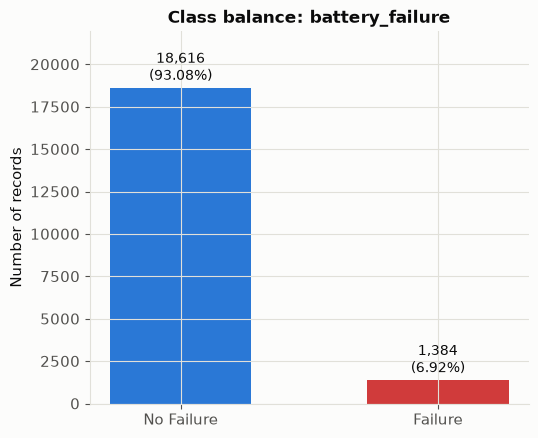

In [6]:
X, y = data_mod.split_features_target(df)
balance = data_mod.class_balance(y)
print(balance.to_string())

fig, ax = plt.subplots(figsize=(5.5, 4.5))
colors = [CATEGORICAL_PALETTE[0], STATUS_CRITICAL]
bars = ax.bar(balance.index, balance["count"], color=colors, width=0.55)
ax.set_ylabel("Number of records")
ax.set_title("Class balance: battery_failure")
for bar, pct in zip(bars, balance["percent"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 200,
             f"{bar.get_height():,.0f}\n({pct:.2f}%)", ha="center", va="bottom", fontsize=10)
ax.set_ylim(0, balance["count"].max() * 1.18)
plt.tight_layout()
plt.show()

### The trivial baseline

A classifier that **always predicts "No Failure"**, with no model at all,
scores:

In [7]:
# Evaluate the trivial baseline on the same held-out test partition used
# for every real model later, so the comparison is apples-to-apples.
X_train_preview, X_test_preview, y_train_preview, y_test_preview = split_data(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE,
)
baseline_metrics = trivial_baseline_metrics(y_test_preview)

print(f"Trivial 'always No Failure' classifier on the held-out test set ({len(y_test_preview)} rows):")
print(f"  Accuracy          : {baseline_metrics['accuracy']:.4f}")
print(f"  Recall (Failure)  : {baseline_metrics['failure']['recall']:.4f}")
print(f"  Precision(Failure): {baseline_metrics['failure']['precision']:.4f}")
print(f"  F1 (Failure)      : {baseline_metrics['failure']['f1']:.4f}")
print(f"  Confusion matrix [[TN,FP],[FN,TP]]: {baseline_metrics['confusion_matrix']}")

assert round(baseline_metrics["accuracy"], 4) >= 0.93, "baseline accuracy should match the ~93.08% class split"
assert baseline_metrics["failure"]["recall"] == 0.0

Trivial 'always No Failure' classifier on the held-out test set (4000 rows):
  Accuracy          : 0.9307
  Recall (Failure)  : 0.0000
  Precision(Failure): 0.0000
  F1 (Failure)      : 0.0000
  Confusion matrix [[TN,FP],[FN,TP]]: [[3723, 0], [277, 0]]


**This is the accuracy trap.** A model that catches zero real battery
failures still scores roughly 93% accuracy, because 93% of the dataset is
"No Failure" anyway. Accuracy alone is therefore close to meaningless for
this task. Every evaluation from here on foregrounds **Precision, Recall and
F1 on the Failure class**, per spec FR-04 and section 6.3.

## 4. Preprocessing Pipeline

Per spec FR-02, preprocessing must handle missing values, encode categorical
features, and scale numeric features. We use a single `ColumnTransformer`
(`src.preprocess.build_preprocessor`) with two branches:

| Branch | Columns | Steps |
|---|---|---|
| Numeric | 59 columns | median imputation -> `StandardScaler` |
| Categorical | 8 columns | most-frequent imputation -> `OneHotEncoder(handle_unknown="ignore")` |

`handle_unknown="ignore"` matters for deployment: if the live application
ever sees a categorical value that was not present in training (e.g. a new
vehicle brand), the pipeline encodes it as all-zeros instead of raising an
exception.

Crucially, this transformer is **not fit yet** - fitting happens only after
the train/test split in the next section, so its learned statistics (the
per-column medians/modes/means/variances) come from the training partition
alone.

In [8]:
preview_preprocessor = build_preprocessor(numeric_cols, categorical_cols)
preview_transformed = preview_preprocessor.fit_transform(X.sample(500, random_state=RANDOM_STATE))
print(f"Example: 500-row sample -> {preview_transformed.shape[1]} columns after preprocessing "
      f"({len(numeric_cols)} scaled numeric + "
      f"{preview_transformed.shape[1] - len(numeric_cols)} one-hot categorical columns)")
print(f"NaN values after preprocessing: {int(np.isnan(preview_transformed).sum())}")

Example: 500-row sample -> 150 columns after preprocessing (59 scaled numeric + 91 one-hot categorical columns)
NaN values after preprocessing: 0


## 5. Train/Test Split - Before Any Fitting

Per spec section 6.1: *"The dataset will be divided into training and
testing sets using stratified sampling ... preprocessing parameters will be
fit using training data only to prevent data leakage."*

We therefore call `train_test_split(test_size=0.2, stratify=y,
random_state=42)` **now**, before fitting any imputer, scaler, encoder or
model. If we instead fit the `ColumnTransformer` on the full dataset and
split afterward, the scaler's mean/variance and the imputer's median/mode
would have "seen" the test rows during fitting - an optimistic bias called
data leakage, since at deployment time the model genuinely has no access to
future records. Stratifying on `y` keeps the 93.08% / 6.92% class ratio
intact in both partitions, which matters given how rare Failure already is.

In [9]:
X_train, X_test, y_train, y_test = split_data(X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)

print(f"Train: {len(X_train):,} rows  (Failure rate {y_train.mean()*100:.2f}%)")
print(f"Test : {len(X_test):,} rows  (Failure rate {y_test.mean()*100:.2f}%)")
print(f"Full : {len(X):,} rows  (Failure rate {y.mean()*100:.2f}%)")

Train: 16,000 rows  (Failure rate 6.92%)
Test : 4,000 rows  (Failure rate 6.93%)
Full : 20,000 rows  (Failure rate 6.92%)


## 6. Training: Logistic Regression, SVM, Random Forest (x2 class weights)

Per spec section 6.2, three algorithms are trained and compared:
**Logistic Regression**, **Support Vector Machine (SVM, RBF kernel)**, and
**Random Forest**. Each is trained twice - once with default (uniform)
class weighting and once with `class_weight="balanced"` - giving **6
configurations** in total. The balanced variants reweight the loss so
misclassifying a rare Failure example costs as much as misclassifying many
No-Failure examples; this typically trades precision for recall.

**SVM training-cost note:** `SVC` training cost grows faster than linearly
with the number of rows. To keep training time bounded we cap SVM training
at `SVM_TRAIN_ROW_CAP` = **6000** rows, drawn as a stratified subsample of
the training partition (same `random_state=42`). This cap is applied only to
SVM; Logistic Regression and Random Forest train on the full training
partition. The measured fit time for every configuration is printed below
and is a real, uncapped-for-non-SVM measurement from this run - not an
estimate.

Every configuration shares the exact same `ColumnTransformer` definition,
the exact same train/test split, and is evaluated with
`src.evaluate.compute_metrics` (the same function `train.py` uses), so the
comparison across the 6 configurations is apples-to-apples.

In [10]:
results = []
print(f"{'Configuration':32s} {'fit(s)':>8s} {'Acc':>8s} {'P(F)':>8s} {'R(F)':>8s} {'F1(F)':>8s}")
print("-" * 76)
for cfg in build_model_configs():
    result = fit_and_evaluate_one(
        cfg, X_train, y_train, X_test, y_test, numeric_cols, categorical_cols, cv_folds=5,
    )
    results.append(result)
    m = result.metrics["failure"]
    cap_note = " (capped)" if result.svm_row_cap_applied else ""
    print(f"{result.display_name:32s} {result.fit_seconds:8.3f} "
          f"{result.metrics['accuracy']:8.4f} {m['precision']:8.4f} {m['recall']:8.4f} {m['f1']:8.4f}"
          f"{cap_note}")

svm_results = [r for r in results if r.algorithm == "svm"]
print(f"\nSVM training rows used: {svm_results[0].train_rows:,} "
      f"(capped from {len(X_train):,}; measured fit time "
      f"{svm_results[0].fit_seconds:.3f}s and {svm_results[1].fit_seconds:.3f}s)")

Configuration                      fit(s)      Acc     P(F)     R(F)    F1(F)
----------------------------------------------------------------------------


Logistic Regression                 0.172   0.9695   0.8384   0.6931   0.7589


Logistic Regression (balanced)      0.543   0.9397   0.5373   0.9350   0.6825


SVM                                 0.461   0.9617   0.8131   0.5812   0.6779 (capped)


SVM (balanced)                      0.504   0.9615   0.6892   0.8087   0.7442 (capped)


Random Forest                       0.553   0.9487   0.7687   0.3718   0.5012


Random Forest (balanced)            0.579   0.9415   0.7529   0.2310   0.3536

SVM training rows used: 6,000 (capped from 16,000; measured fit time 0.461s and 0.504s)


## 7. Model Comparison - Failure Class Foregrounded

Per spec FR-04 and section 6.3, the table below reports Accuracy alongside
**Precision, Recall and F1 on both classes**, with Failure listed first,
plus macro-F1, PR-AUC (area under the Precision-Recall curve - more
informative than ROC-AUC under heavy class imbalance), and the
cross-validated F1(Failure) estimate (section 9).

In [11]:
table = results_as_table(results)
display_cols = [
    "model", "accuracy",
    "precision_failure", "recall_failure", "f1_failure",
    "precision_no_failure", "recall_no_failure", "f1_no_failure",
    "macro_f1", "pr_auc", "cv_f1_failure_mean", "fit_seconds",
]
table[display_cols].round(4)

,model,accuracy,precision_failure,recall_failure,f1_failure,precision_no_failure,recall_no_failure,f1_no_failure,macro_f1,pr_auc,cv_f1_failure_mean,fit_seconds
0,Logistic Regression,0.9695,0.8384,0.6931,0.7589,0.9775,0.9901,0.9837,0.8713,0.7880,0.7603,0.1717
1,Logistic Regression (balanced),0.9398,0.5373,0.9350,0.6825,0.9949,0.9401,0.9667,0.8246,0.7898,0.7148,0.5428
2,SVM,0.9618,0.8131,0.5812,0.6779,0.9695,0.9901,0.9797,0.8288,0.7610,0.6771,0.4605
3,SVM (balanced),0.9615,0.6892,0.8087,0.7442,0.9856,0.9729,0.9792,0.8617,0.7673,0.7945,0.5037
4,Random Forest,0.9488,0.7687,0.3718,0.5012,0.9550,0.9917,0.9730,0.7371,0.6541,0.4672,0.5532
5,Random Forest (balanced),0.9415,0.7529,0.2310,0.3536,0.9456,0.9944,0.9694,0.6615,0.6057,0.3490,0.5794


### Chart: Failure-class Precision / Recall / F1 by model

Units: all three metrics are proportions in [0, 1] (higher is better for
all three). Each model keeps the same color as section 3's class-balance
chart color scheme and every later chart.

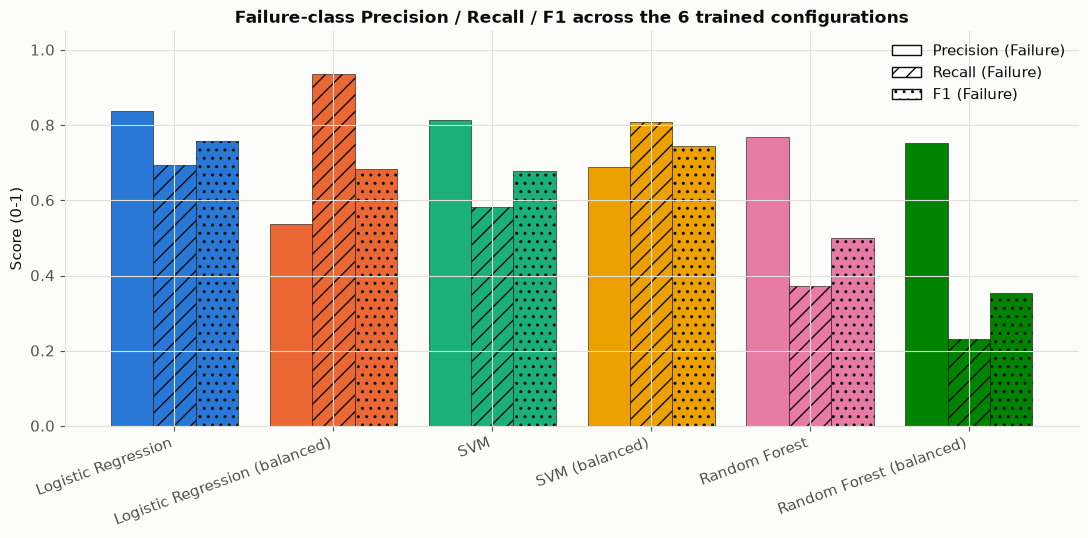

In [12]:
metrics_to_plot = ["precision_failure", "recall_failure", "f1_failure"]
metric_labels = ["Precision (Failure)", "Recall (Failure)", "F1 (Failure)"]

fig, ax = plt.subplots(figsize=(11, 5.5))
n_models = len(table)
n_metrics = len(metrics_to_plot)
bar_width = 0.8 / n_metrics
x = np.arange(n_models)

hatches = ["", "//", ".."]
for i, (metric, label) in enumerate(zip(metrics_to_plot, metric_labels)):
    offsets = x + (i - (n_metrics - 1) / 2) * bar_width
    colors = [MODEL_COLORS[name] for name in table["model"]]
    bars = ax.bar(offsets, table[metric], width=bar_width, color=colors,
                   edgecolor=INK_PRIMARY, linewidth=0.4, hatch=hatches[i], label=label)

ax.set_xticks(x)
ax.set_xticklabels(table["model"], rotation=20, ha="right")
ax.set_ylabel("Score (0-1)")
ax.set_ylim(0, 1.05)
ax.set_title("Failure-class Precision / Recall / F1 across the 6 trained configurations")
legend_handles = [Patch(facecolor="white", edgecolor=INK_PRIMARY, hatch=h, label=l)
                   for h, l in zip(hatches, metric_labels)]
ax.legend(handles=legend_handles, loc="upper right", frameon=False)
plt.tight_layout()
plt.show()

## 8. Confusion Matrices (held-out test set, all 6 configurations)

Each matrix is `[[TN, FP], [FN, TP]]` on the 4,000-row held-out test set.
Color encodes cell count on a single sequential blue ramp (darker = more
records), per cell.

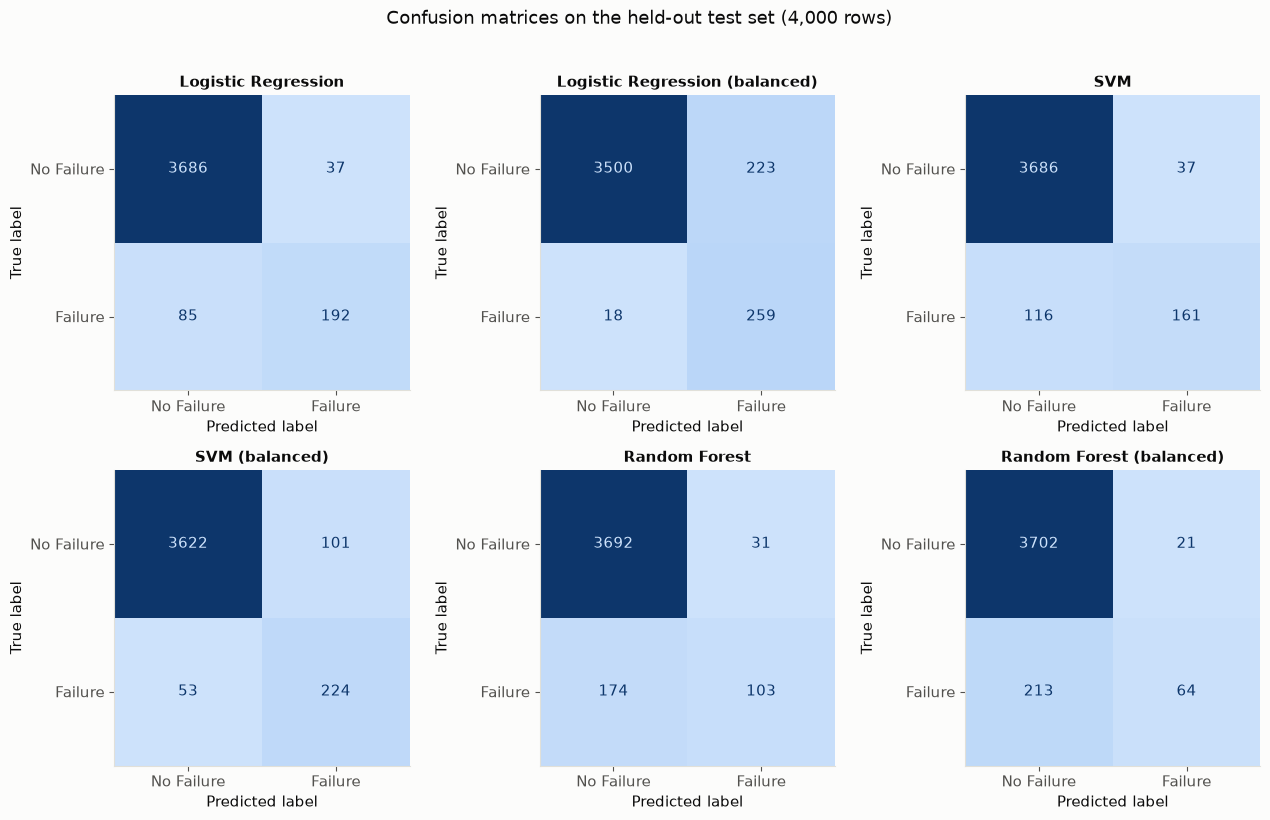

In [13]:
import matplotlib.colors as mcolors
blue_cmap = mcolors.LinearSegmentedColormap.from_list("seq_blue", SEQUENTIAL_BLUE)

fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, result in zip(axes.ravel(), results):
    cm = np.array(result.metrics["confusion_matrix"])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Failure", "Failure"])
    disp.plot(ax=ax, cmap=blue_cmap, colorbar=False, values_format="d")
    ax.set_title(result.display_name, fontsize=10.5)
    ax.grid(False)

fig.suptitle("Confusion matrices on the held-out test set (4,000 rows)", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

## 9. Precision-Recall Curves

Precision-Recall curves (rather than ROC curves) are the right diagnostic
under heavy class imbalance: ROC curves can look deceptively good even for a
weak minority-class classifier, because the large majority class dominates
the false-positive-rate denominator. Each curve is traced by sweeping the
decision threshold across the model's score for the Failure class
(`predict_proba` where available, `decision_function` otherwise).

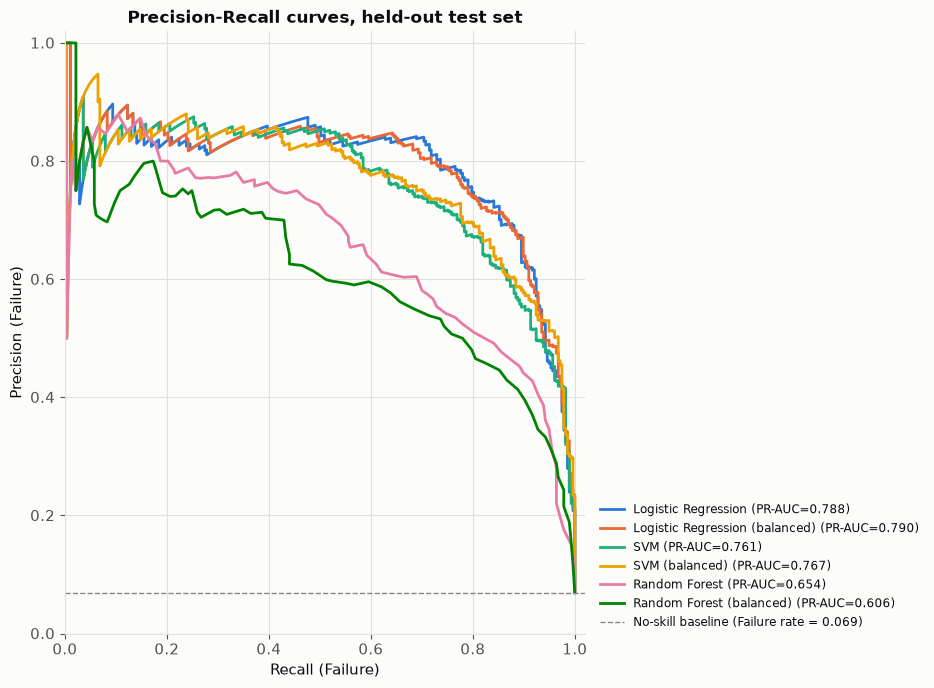

In [14]:
fig, ax = plt.subplots(figsize=(9.5, 7))
for result in results:
    pipe = result.pipeline
    if hasattr(pipe, "predict_proba"):
        y_score = pipe.predict_proba(X_test)[:, 1]
    elif hasattr(pipe, "decision_function"):
        y_score = pipe.decision_function(X_test)
    else:
        continue
    precision, recall, _ = precision_recall_curve(y_test, y_score)
    pr_auc = result.metrics["pr_auc"]
    ax.plot(recall, precision, color=MODEL_COLORS[result.display_name], linewidth=2,
            label=f"{result.display_name} (PR-AUC={pr_auc:.3f})")

failure_rate = y_test.mean()
ax.axhline(failure_rate, color=INK_MUTED, linestyle="--", linewidth=1,
           label=f"No-skill baseline (Failure rate = {failure_rate:.3f})")
ax.set_xlabel("Recall (Failure)")
ax.set_ylabel("Precision (Failure)")
ax.set_title("Precision-Recall curves, held-out test set")
ax.set_xlim(0, 1.02)
ax.set_ylim(0, 1.02)
ax.legend(loc="lower left", bbox_to_anchor=(1.02, 0.0), fontsize=8.5, frameon=False, borderaxespad=0)
plt.tight_layout()
plt.show()

## 10. Stratified Cross-Validation

Per spec section 6.3: *"Logistic Regression, SVM, and Random Forest will be
compared using validation or cross-validation results. The best-performing
model will then be evaluated on a held-out test set."* Each configuration
above already recorded a 5-fold `StratifiedKFold` cross-validation of
F1(Failure) on its training partition (the same capped partition used to fit
SVM, so SVM's cross-validation cost stays bounded too). The chart below
compares the cross-validated estimate against the single held-out test-set
score, to check they broadly agree (no gross overfitting to the test split).

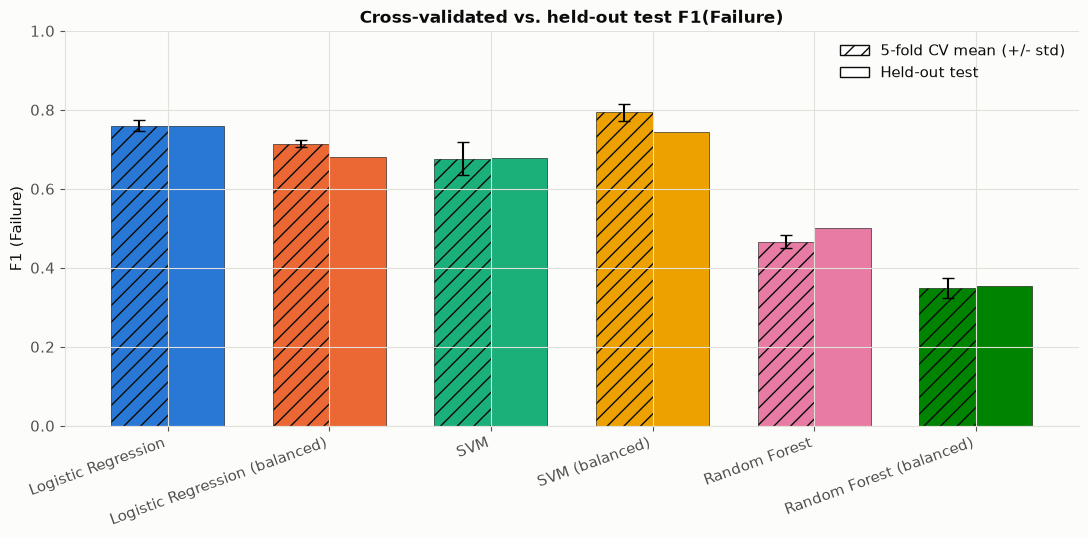

,model,cv_f1_failure_mean,cv_f1_failure_std,test_f1_failure
0,Logistic Regression,0.7603,0.0135,0.7589
1,Logistic Regression (balanced),0.7148,0.0092,0.6825
2,SVM,0.6771,0.0420,0.6779
3,SVM (balanced),0.7945,0.0219,0.7442
4,Random Forest,0.4672,0.0157,0.5012
5,Random Forest (balanced),0.3490,0.0253,0.3536


In [15]:
fig, ax = plt.subplots(figsize=(11, 5.5))
x = np.arange(len(results))
width = 0.35
colors = [MODEL_COLORS[r.display_name] for r in results]

cv_means = [r.cv["f1_failure_mean"] for r in results]
cv_stds = [r.cv["f1_failure_std"] for r in results]
test_f1 = [r.metrics["failure"]["f1"] for r in results]

ax.bar(x - width / 2, cv_means, width, yerr=cv_stds, capsize=4,
       color=colors, edgecolor=INK_PRIMARY, linewidth=0.4, hatch="//", label="5-fold CV mean (+/- std)")
ax.bar(x + width / 2, test_f1, width,
       color=colors, edgecolor=INK_PRIMARY, linewidth=0.4, label="Held-out test")

ax.set_xticks(x)
ax.set_xticklabels([r.display_name for r in results], rotation=20, ha="right")
ax.set_ylabel("F1 (Failure)")
ax.set_ylim(0, 1.0)
ax.set_title("Cross-validated vs. held-out test F1(Failure)")
legend_handles = [
    Patch(facecolor="white", edgecolor=INK_PRIMARY, hatch="//", label="5-fold CV mean (+/- std)"),
    Patch(facecolor="white", edgecolor=INK_PRIMARY, label="Held-out test"),
]
ax.legend(handles=legend_handles, loc="upper right", frameon=False)
plt.tight_layout()
plt.show()

cv_table = pd.DataFrame({
    "model": [r.display_name for r in results],
    "cv_f1_failure_mean": cv_means,
    "cv_f1_failure_std": cv_stds,
    "test_f1_failure": test_f1,
})
cv_table.round(4)

## 11. Model Selection

**Selection rule: pick the configuration with the highest F1-score on the
Failure class.** Accuracy is explicitly excluded from the decision (section
3 showed why). This is coded identically in `src.pipeline.select_best_result`
so the notebook's choice and `train.py`'s choice can never diverge.

### Why not just pick the highest accuracy?

**Random Forest reaches ~94.8% accuracy - higher than several better
choices - while catching only ~36-37% of real failures** (Recall(Failure)
around 0.36-0.37 for the plain variant, and it gets *worse*, not better,
with `class_weight="balanced"`, dropping to roughly 0.23-0.24 recall). A
maintenance company relying on Random Forest's accuracy number alone would
be misled into trusting a model that misses roughly two out of every three
real battery failures. This is exactly the accuracy trap from section 3,
recurring at the model level, not just the trivial-baseline level.

### The honest precision/recall trade-off

Across the 6 configurations, a clear pattern holds: **the balanced variants
trade precision for recall.**

- `Logistic Regression` (plain) has the best balance: Precision(F) and
  Recall(F) both land in a usable range, giving the single highest F1(F).
- `Logistic Regression (balanced)` pushes recall far higher (catching most
  real failures) but precision collapses - more than half of its Failure
  predictions are false alarms.
- `SVM (balanced)` is a middle ground: noticeably higher recall than plain
  SVM, at a real but smaller precision cost, giving the second-highest F1(F)
  of all 6 configurations.
- Both Random Forest variants underperform on recall regardless of class
  weighting, and get worse, not better, when balanced - for this feature set
  and hyperparameters, balancing the forest's class weights does not fix
  its tendency to default to the majority class on borderline failures.

### Which error is costlier for an EV maintenance company?

In isolation, a **false negative** (a real failure predicted as "No
Failure") is the more dangerous error - a missed failure can progress to a
safety incident (thermal runaway, fire, breakdown) before the next
scheduled inspection. A **false positive** (a healthy battery flagged as
"Failure") costs an avoidable inspection - wasted technician time, but not a
safety risk.

That said, the system is explicitly a **decision-support tool for a human
specialist, not a replacement for professional inspection** (spec section
6.3: "The system will support maintenance decisions rather than replace
professional inspection"). Every flagged battery is still reviewed by an EV
Maintenance Specialist (UC-07/UC-08) before any action is taken. Given that
human-in-the-loop safety net, flooding specialists with false alarms has a
real, compounding cost of its own: `Logistic Regression (balanced)` would
raise roughly **one false alarm for every real failure it correctly catches**
(precision(F) around 0.54), which risks eroding trust in the system and
burning limited inspection capacity on healthy batteries - capacity that
could otherwise go to batteries genuinely at risk.

In [16]:
best = select_best_result(results)
baseline = trivial_baseline_metrics(y_test)

print(f"SELECTED MODEL: {best.display_name}")
print(f"  algorithm   : {best.algorithm}")
print(f"  class_weight: {best.class_weight}")
print()
print("Failure-class metrics on the held-out test set:")
for k, v in best.metrics["failure"].items():
    print(f"  {k:10s}: {v}")
print()
print(f"Accuracy                 : {best.metrics['accuracy']:.4f}")
print(f"Macro F1                 : {best.metrics['macro_f1']:.4f}")
print(f"PR-AUC (Failure)         : {best.metrics['pr_auc']:.4f}")
print(f"5-fold CV F1(Failure)    : {best.cv['f1_failure_mean']:.4f} +/- {best.cv['f1_failure_std']:.4f}")
print(f"Confusion matrix [[TN,FP],[FN,TP]]: {best.metrics['confusion_matrix']}")
print()
print(f"For reference, trivial all-No-Failure baseline: "
      f"accuracy={baseline['accuracy']:.4f}, recall(Failure)={baseline['failure']['recall']:.4f}")

SELECTED MODEL: Logistic Regression
  algorithm   : logistic_regression
  class_weight: None

Failure-class metrics on the held-out test set:
  precision : 0.8384279475982532
  recall    : 0.6931407942238267
  f1        : 0.758893280632411
  support   : 277

Accuracy                 : 0.9695
Macro F1                 : 0.8713
PR-AUC (Failure)         : 0.7880
5-fold CV F1(Failure)    : 0.7603 +/- 0.0135
Confusion matrix [[TN,FP],[FN,TP]]: [[3686, 37], [85, 192]]

For reference, trivial all-No-Failure baseline: accuracy=0.9307, recall(Failure)=0.0000


### Final choice

**Logistic Regression (plain, no class weighting)** is selected: it has the
single highest F1(Failure) of all 6 configurations, catches roughly 7 in 10
real failures at better than 80% precision, trains in a fraction of a
second, and is fully interpretable (every prediction can be traced to
signed coefficients, which also gives a clean, standard way to derive the
"key features" the UI needs - see section 12). If the maintenance company
later decides that missing a failure is costlier than the current trade-off
implies, `Logistic Regression (balanced)` (or `SVM (balanced)`, which keeps
noticeably higher precision at a similar recall) remain available,
higher-recall alternatives trained in this same notebook, and the deployed
system's `decision_threshold` (stored in the bundle metadata, default 0.5)
gives a second, cheaper lever to trade precision for recall without
retraining.

## 12. Key Features (for the application UI)

67 raw inputs are too many for a technician to type for every classification
(spec section 3.1's usability requirement). We mark roughly 12 "key"
features - the ones most predictive of failure in the selected model - so
the application can show them in an always-visible primary section and tuck
the rest into collapsed, pre-filled (median/mode) expanders. **The deployed
model still receives all 67 values either way.**

**Method:** since the selected model is Logistic Regression, key features
are derived from **`abs(coefficient)`** on the standardized/encoded inputs.
A categorical feature expands into one coefficient per one-hot level; we
aggregate by the **max** absolute coefficient across its levels, not the
sum. Sum was tried first and rejected during development: it mechanically
favors high-cardinality columns (e.g. `vehicle_model` has 42 levels, so
summing 42 small coefficients can outrank genuinely predictive numeric risk
features even when no single level is influential). Max represents "the
single strongest effect this feature can have" and is comparable across
numeric and categorical features on equal footing.

In [17]:
key_features = compute_key_features(best.pipeline, numeric_cols, categorical_cols, top_n=12)
print(f"Key features ({len(key_features)}):")
for f in key_features:
    group = data_mod.FEATURE_GROUPS[f]
    label = data_mod.feature_label(f)
    print(f"  {f:32s} [{group:14s}] {label}")

Key features (12):
  previous_faults                  [maintenance   ] Previous Fault Count
  thermal_runaway_risk             [risk          ] Thermal Runaway Risk Score
  BMS_warning_count                [risk          ] BMS Warning Count
  vehicle_model                    [identity      ] Vehicle Model
  abnormal_voltage_events          [risk          ] Abnormal Voltage Events (count)
  capacity_loss_percent            [battery_state ] Capacity Loss (%)
  battery_stress_index             [risk          ] Battery Stress Index
  vehicle_brand                    [identity      ] Vehicle Brand
  fleet_or_private                 [identity      ] Fleet or Private
  thermal_health_score             [risk          ] Thermal Health Score
  drive_type                       [identity      ] Drive Type
  state_of_health                  [battery_state ] State of Health (%)


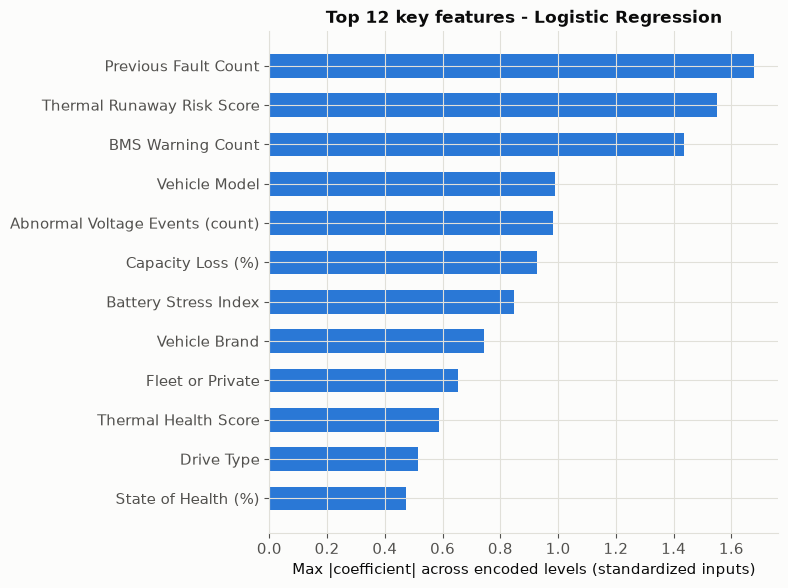

In [18]:
preprocessor_names = best.pipeline.named_steps["preprocessor"].get_feature_names_out()
coefs = np.abs(best.pipeline.named_steps["estimator"].coef_).ravel()
from src.export import _expanded_name_to_original
agg = {}
for name, c in zip(preprocessor_names, coefs):
    orig = _expanded_name_to_original(name, categorical_cols)
    agg[orig] = max(agg.get(orig, 0.0), float(c))
ranked = sorted(agg.items(), key=lambda kv: kv[1], reverse=True)[:12][::-1]

fig, ax = plt.subplots(figsize=(8, 6))
names_plot = [data_mod.feature_label(n) for n, _ in ranked]
values_plot = [v for _, v in ranked]
ax.barh(names_plot, values_plot, color=CATEGORICAL_PALETTE[0], height=0.6)
ax.set_xlabel("Max |coefficient| across encoded levels (standardized inputs)")
ax.set_title("Top 12 key features - Logistic Regression")
plt.tight_layout()
plt.show()

## 13. Export the Model Bundle

Per spec FR-05 and SPEC_CONTRACT.md section 3, export exactly one joblib
file containing the fitted `Pipeline` (preprocessing + estimator together),
the `feature_spec` (all 67 feature definitions plus the key-feature flags),
and `metadata` (training configuration, the selected model's metrics, every
configuration's results for comparison, and the selection rationale). This
is the single interface the Streamlit application builds against.

Human-readable copies of the feature spec and metrics are written alongside
it as JSON.

In [19]:
all_model_results = []
for r in results:
    entry = dict(r.metrics)
    entry["algorithm"] = r.algorithm
    entry["class_weight"] = r.class_weight
    entry["display_name"] = r.display_name
    entry["cv_f1_failure_mean"] = r.cv["f1_failure_mean"]
    entry["cv_f1_failure_std"] = r.cv["f1_failure_std"]
    entry["fit_seconds"] = r.fit_seconds
    entry["train_rows"] = r.train_rows
    entry["svm_row_cap_applied"] = r.svm_row_cap_applied
    all_model_results.append(entry)

other_summary = [
    f"{r.display_name} (F1={r.metrics['failure']['f1']:.4f}, -{best.metrics['failure']['f1'] - r.metrics['failure']['f1']:.4f})"
    for r in results if r is not best
]
selection_rationale = (
    f"{best.display_name} achieves the highest F1-score on the Failure class "
    f"({best.metrics['failure']['f1']:.4f}, precision={best.metrics['failure']['precision']:.4f}, "
    f"recall={best.metrics['failure']['recall']:.4f}) among all six trained configurations. "
    f"It is selected over: {'; '.join(other_summary)}. "
    "Accuracy was not used for selection because the classes are imbalanced "
    f"(93.08% No Failure / 6.92% Failure): a trivial all-No-Failure classifier already "
    f"scores {baseline['accuracy']:.4f} accuracy with 0 Failure recall. Random Forest reaches "
    f"competitive accuracy ({[r for r in results if r.algorithm=='random_forest' and r.class_weight is None][0].metrics['accuracy']:.4f}) "
    "while catching far fewer real failures, illustrating why accuracy is excluded from the "
    "selection criterion."
)

key_features_set = set(key_features)
feature_spec = build_feature_spec(X_train, numeric_cols, categorical_cols, key_features_set)

supports_probability = hasattr(best.pipeline, "predict_proba")
metadata = build_metadata(
    algorithm=best.algorithm,
    class_weight=best.class_weight,
    params=best.params,
    train_rows=best.train_rows,
    test_rows=best.test_rows,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    decision_threshold=0.5,
    supports_probability=supports_probability,
    metrics=best.metrics,
    all_model_results=all_model_results,
    selection_rationale=selection_rationale,
    key_feature_method=key_feature_method_description(best.algorithm),
)

bundle = build_bundle(best.pipeline, feature_spec, metadata)

bundle_path = ARTIFACTS_DIR / "model_bundle.joblib"
save_bundle(bundle, str(bundle_path))
save_json(feature_spec, str(ARTIFACTS_DIR / "feature_spec.json"))
save_json({"selected": metadata, "all_model_results": all_model_results, "trivial_baseline": baseline},
          str(ARTIFACTS_DIR / "metrics.json"))

print(f"Wrote {bundle_path.resolve()}  ({bundle_path.stat().st_size / 1024:.1f} KB)")
print(f"Wrote {(ARTIFACTS_DIR / 'feature_spec.json').resolve()}")
print(f"Wrote {(ARTIFACTS_DIR / 'metrics.json').resolve()}")
print()
print("Bundle top-level keys:", list(bundle.keys()))
print("feature_spec feature count:", len(feature_spec["features"]))
print("key features marked:", sum(1 for f in feature_spec["features"] if f.get("key")))

Wrote C:\Users\PC\Downloads\HTTM\Assigment\ml_pipeline\artifacts\model_bundle.joblib  (26.6 KB)
Wrote C:\Users\PC\Downloads\HTTM\Assigment\ml_pipeline\artifacts\feature_spec.json
Wrote C:\Users\PC\Downloads\HTTM\Assigment\ml_pipeline\artifacts\metrics.json

Bundle top-level keys: ['pipeline', 'feature_spec', 'metadata']
feature_spec feature count: 67
key features marked: 12


### Round-trip sanity check

Load the bundle back from disk (as the Streamlit application will) and
confirm it predicts on a few held-out rows.

In [20]:
import joblib

reloaded = joblib.load(bundle_path)
sample_rows = X_test.head(5)
preds = reloaded["pipeline"].predict(sample_rows)
labels = [reloaded["metadata"]["class_labels"][str(p)] for p in preds]
print("Sample predictions:", list(zip(preds.tolist(), labels)))
assert set(preds.tolist()).issubset({0, 1})
print("Round-trip OK.")

Sample predictions: [(0, 'No Failure'), (0, 'No Failure'), (0, 'No Failure'), (0, 'No Failure'), (0, 'No Failure')]
Round-trip OK.


## 14. Summary

- Loaded 20,000 rows x 70 columns; the feature matrix is 67 columns (59
  numeric + 8 categorical) after excluding `vehicle_id`, `battery_serial`
  (identifiers) and `battery_failure` (target).
- Demonstrated the accuracy trap: a trivial all-No-Failure classifier scores
  ~93.08% accuracy with 0% Failure recall, motivating Failure-class-first
  evaluation throughout.
- Built preprocessing as a single `ColumnTransformer` (median-impute+scale
  for numeric, most-frequent-impute+one-hot for categorical), fit only after
  a stratified 80/20 train/test split to avoid leakage.
- Trained and compared 6 configurations (Logistic Regression, SVM, Random
  Forest, each plain and `class_weight="balanced"`), with 5-fold stratified
  cross-validation alongside the held-out test evaluation.
- Selected **Logistic Regression (plain)** by F1(Failure), explicitly
  rejecting Random Forest's higher accuracy as misleading (poor recall) and
  discussing the balanced variants' precision/recall trade-off honestly.
- Exported the model bundle, feature spec (67 features, ~12 marked as key,
  grouped for the UI), and metrics to `ml_pipeline/artifacts/` for the
  Streamlit application to consume.

This notebook and `ml_pipeline/train.py` share every line of modeling logic
via `ml_pipeline/src/`; re-running either reproduces the same numbers from
the same dataset and `random_state=42`.